# EC data analysis with corresponding image data

This notebook plots important elecetrochemical data for CO2ELY and compares it to concurrent and potentially relevant imaging results

TODO:
1. add Bernhard data as reference

In [1]:
#import relevant moduls and define general filepaths
import json
import os
import socket
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    
processing_path = os.path.join(toppath, 'processing')
EC_path = os.path.join(toppath, 'EC_lab_files')
overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))

#go and fetch some tools from the git repo and come back
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)

import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np

deffontsize = mpl.rcParams["font.size"]
print(deffontsize)



10.0


In [2]:
# normalize data versus mormalized charg
def get_principal_data(ECdata):
    dims = np.array([ECdata[i].dims['t'] for i in range(len(ECdata))])
    I = np.zeros(dims.sum())
    timestamps = I.copy()
    E = I.copy()
    Re = I.copy()
    Im = I.copy()

    I[:dims[0]] = ECdata[0]['I'].data
    # timestamps[:dims[0]] = ECdata[0]['t'].data
    timestamps[:dims[0]] = ECdata[0]['timestamp (utc)'].data
    E[:dims[0]] = ECdata[0]['$E_{we}$'].data
    Im[:dims[0]] = ECdata[0]['-Im(Z)'].data
    Re[:dims[0]] = ECdata[0]['Re(Z)'].data

    for i in range(1,len(dims)):
        I[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['I'].data
        timestamps[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['timestamp (utc)'].data
        # timestamps[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['t'].data +ECdata[i-1]['t'].data.max()
        E[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['$E_{we}$'].data
        Im[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['-Im(Z)'].data
        Re[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['Re(Z)'].data     
    # print(timestamps[0])
    # print(timestamps.min())
    
    order = timestamps.argsort()
    t0 = timestamps[timestamps>0].min()
    print(t0)
    I = I[order]
    E = E[order]
    Im = Im[order]
    Re = Re[order]
    timestamps = timestamps[order]
    time = timestamps - t0
    
    
    dt = np.gradient(time)
    Q = np.cumsum(-I*dt)
    return Q, I, E, time, Im, Re, timestamps

In [3]:
#TODO: wrap into sample function, time all in min
def plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50)):

    if unit == 'min':
        tf = 60
    if unit == 's':
        tf = 1


    mpl.rcParams["font.size"] = 24
    fig, ax = plt.subplots(1,3, figsize=(35,12))
    fig.tight_layout(pad=7)
    
    ax2l = ax[0].twinx()

    #plot potential and current in left panel
    # TODO: consider multiple files with timestamps
    # for d in ECdata:
    #     d['$E_{we}$'].plot(ax=ax[0], color='k', label='$E_{we}$')
    #     d['I'].plot(ax=ax2l, color='r', label='I')
    ax[0].plot(time/tf, E,color='k',marker='.', label='$E_{we}$', linestyle='')
    ax2l.plot(time/tf, I,color='r',marker='.', label='I', linestyle='')
    ax[0].set_xlim(0,time.max()/tf)
    ax2l.set_xlim(0,time.max()/tf)
    ax[0].set_xlabel('time ['+unit+']')
    ax[0].set_ylabel('$E_{we}$ [V]')
    ax2l.set_ylabel('I [mA]')
    ax[0].legend(loc='lower left')
    ax2l.legend(loc='lower right')
    plt.title(sample)

    #HFR to the middle panel
    # HFR_color_plot_to_axis(ECdata[0], ax[1], fig, markersize=50, yl=(-10,40), unit='s')
    tl = (0,time.max()/tf)
    im = ax[1].scatter(Re, Im, c=time/tf, cmap = cm.viridis, marker='o', s=30, vmin=tl[0], vmax=tl[1])
    ax[1].axhline(0, color='k', linewidth=0.5)
    ax[1].set_xlim(xl[0],xl[1])
    ax[1].set_ylim(yl[0],yl[1])
    ax[1].set_xlabel('Re(Z) [$\Omega$]')
    ax[1].set_ylabel('-Im(Z) [$\Omega$]')

    divider = make_axes_locatable(ax[1])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical', label='time ['+unit+']')

    # power vs charge
    ax[2].plot(Q/1000, E*I)
    ax[2].set_xlabel('charge [As]')
    ax[2].set_ylabel('power [mW]')
    ax[2].set_xlim(0,Q.max()/1000)



In [4]:
# global variables and dicts
charge_dict = {}

## Cell 5II
### short description

Potentiostatic operation 3.5V


In [5]:
# load data TODO wrap into function and provided small dossier as dict
sample = '5II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps}

1667263451.5826


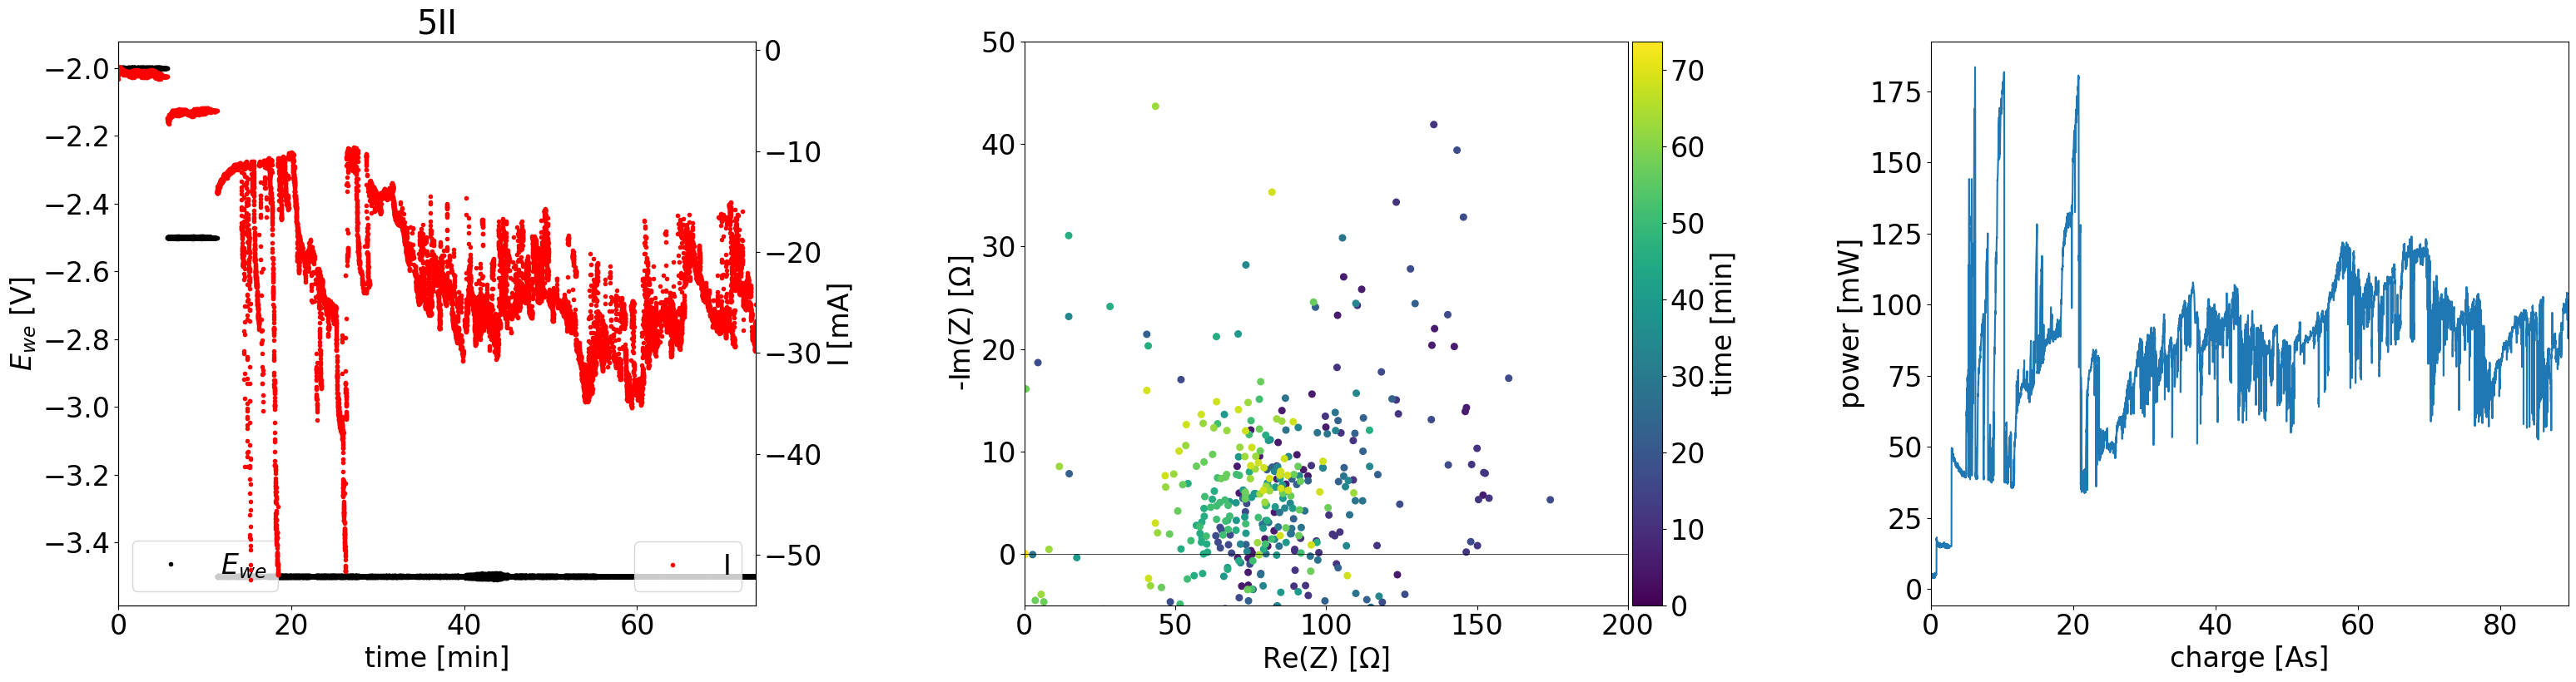

In [6]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 3II
### short description

Potentiostatic operation 3.5V


In [9]:
# load data TODO wrap into function and provided small dossier as dict
sample = '3II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps}

1667258365.5576


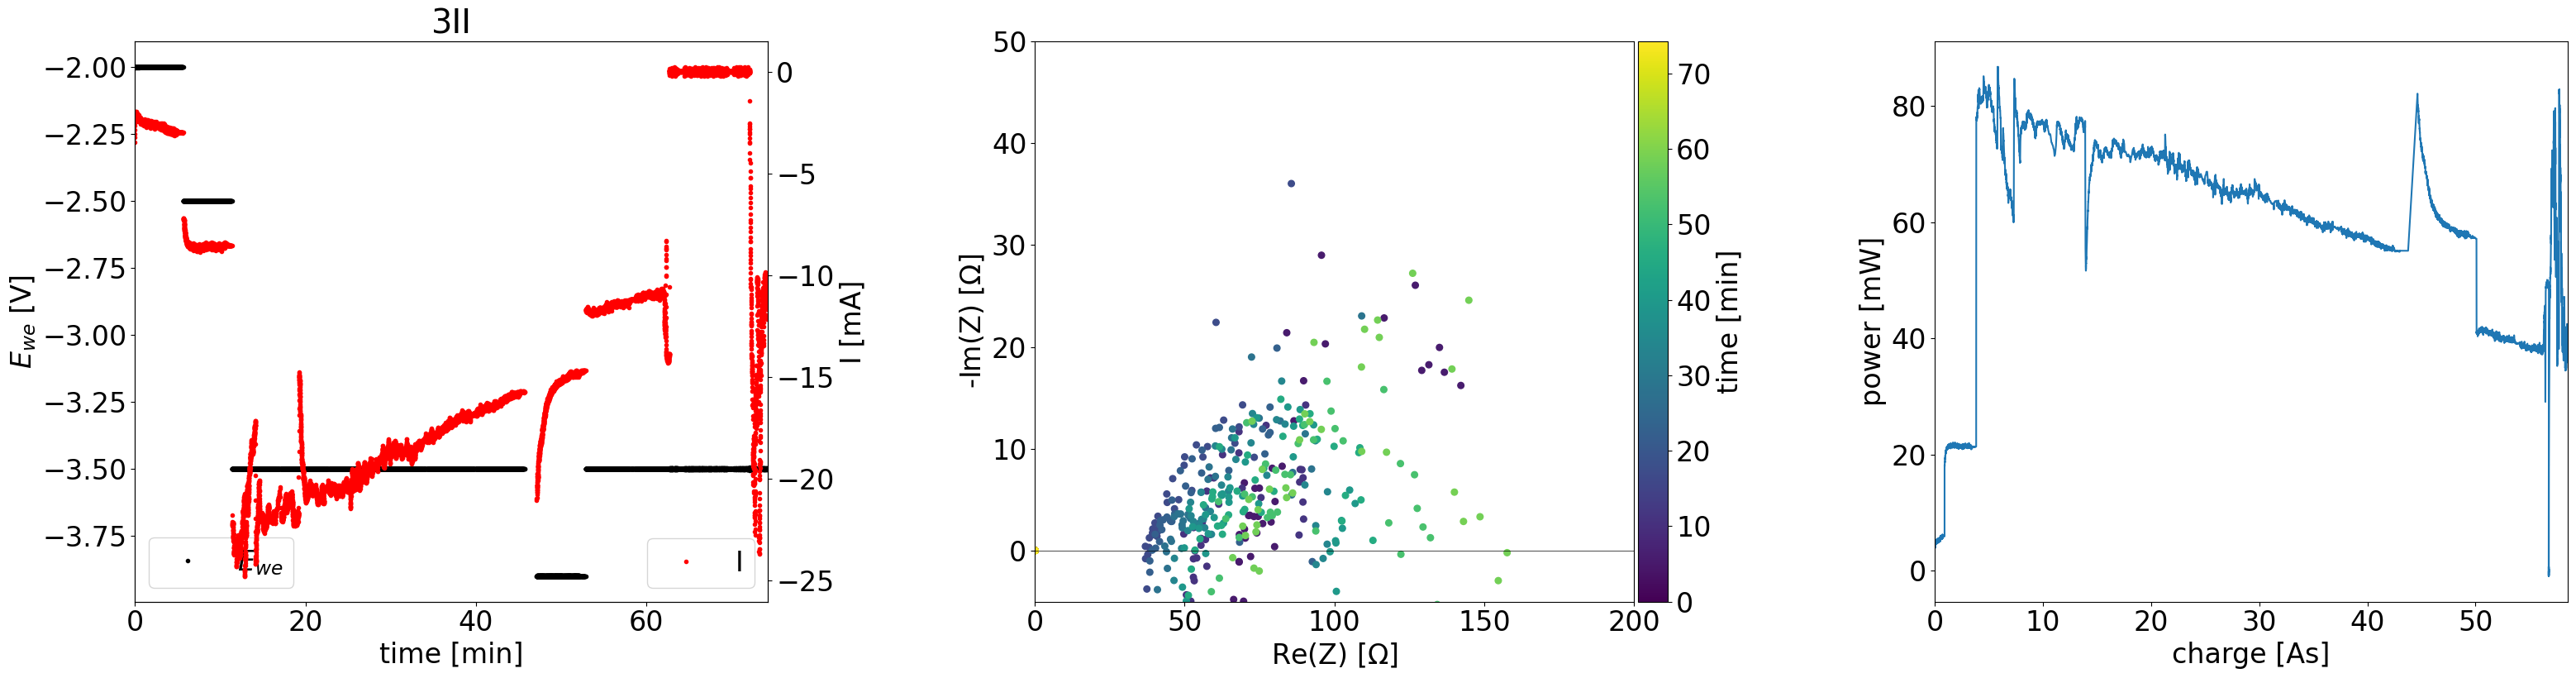

In [10]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 4
### short description

Galvanostatic operation 3mA<br />


In [11]:
# load data TODO wrap into function and provided small dossier as dict
sample = '4'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps}

1667236019.7556


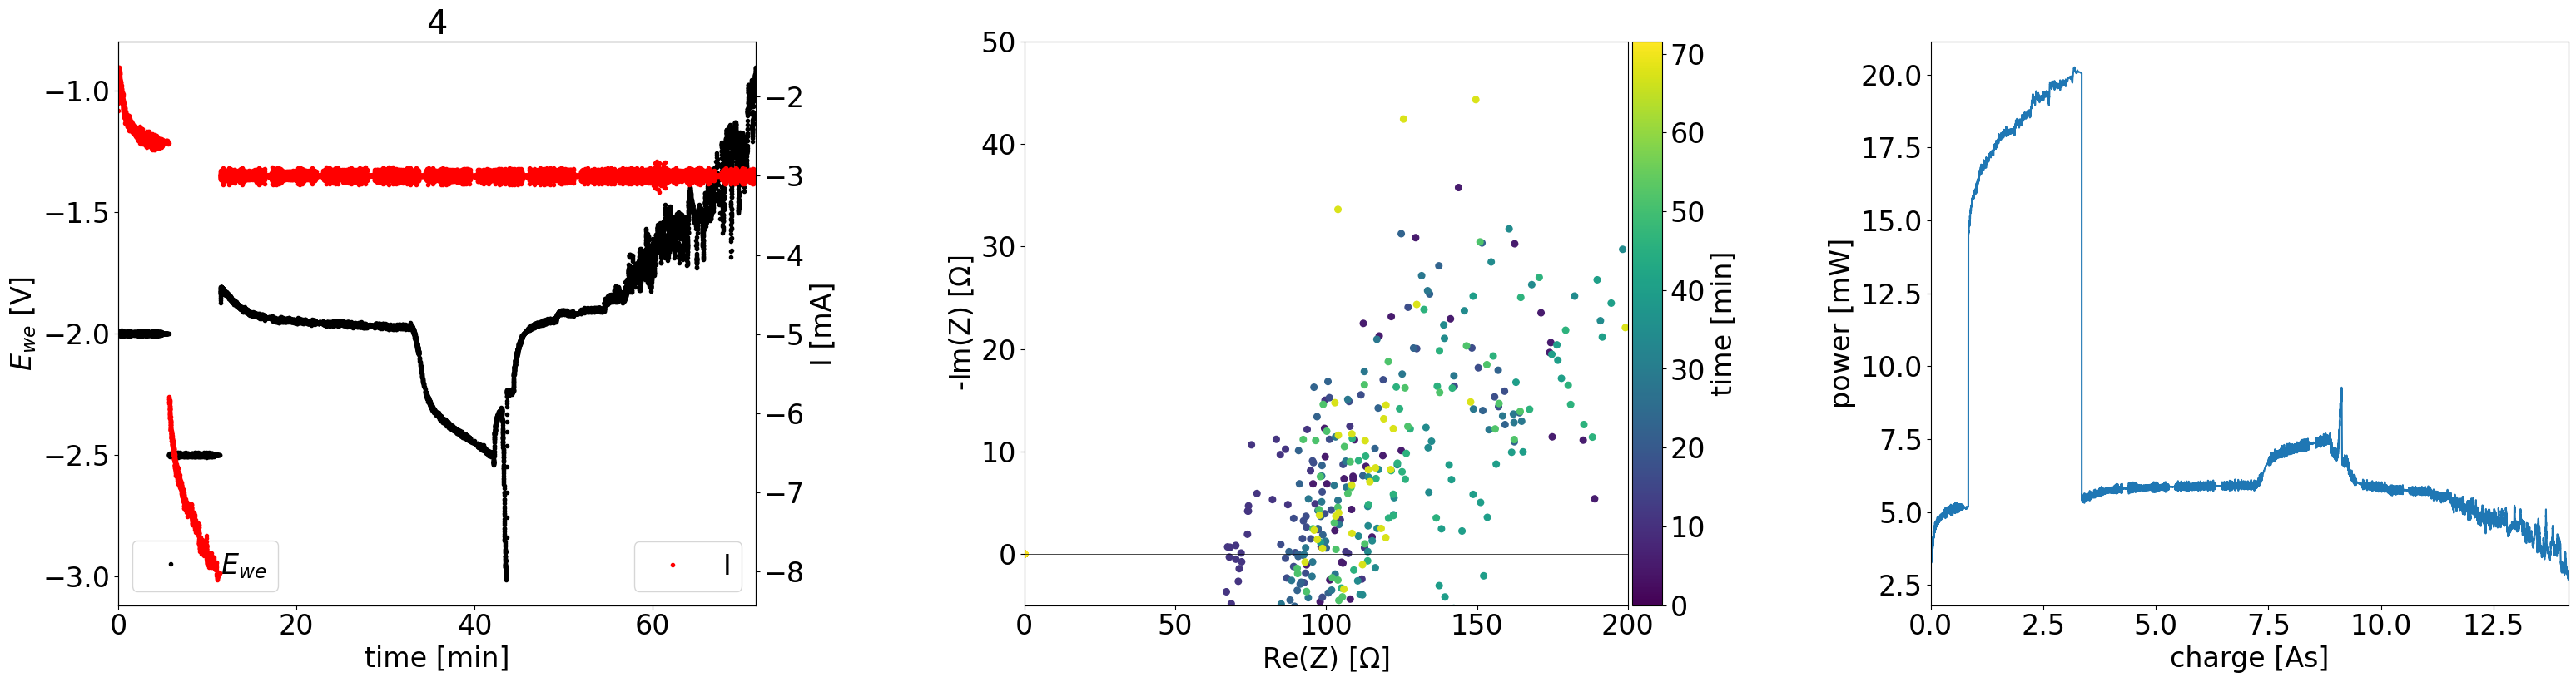

In [12]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 6
### short description

Galvanostatic operation 5mA<br />



In [13]:
# load data TODO wrap into function and provided small dossier as dict
sample = '6'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps}

1667253068.8336


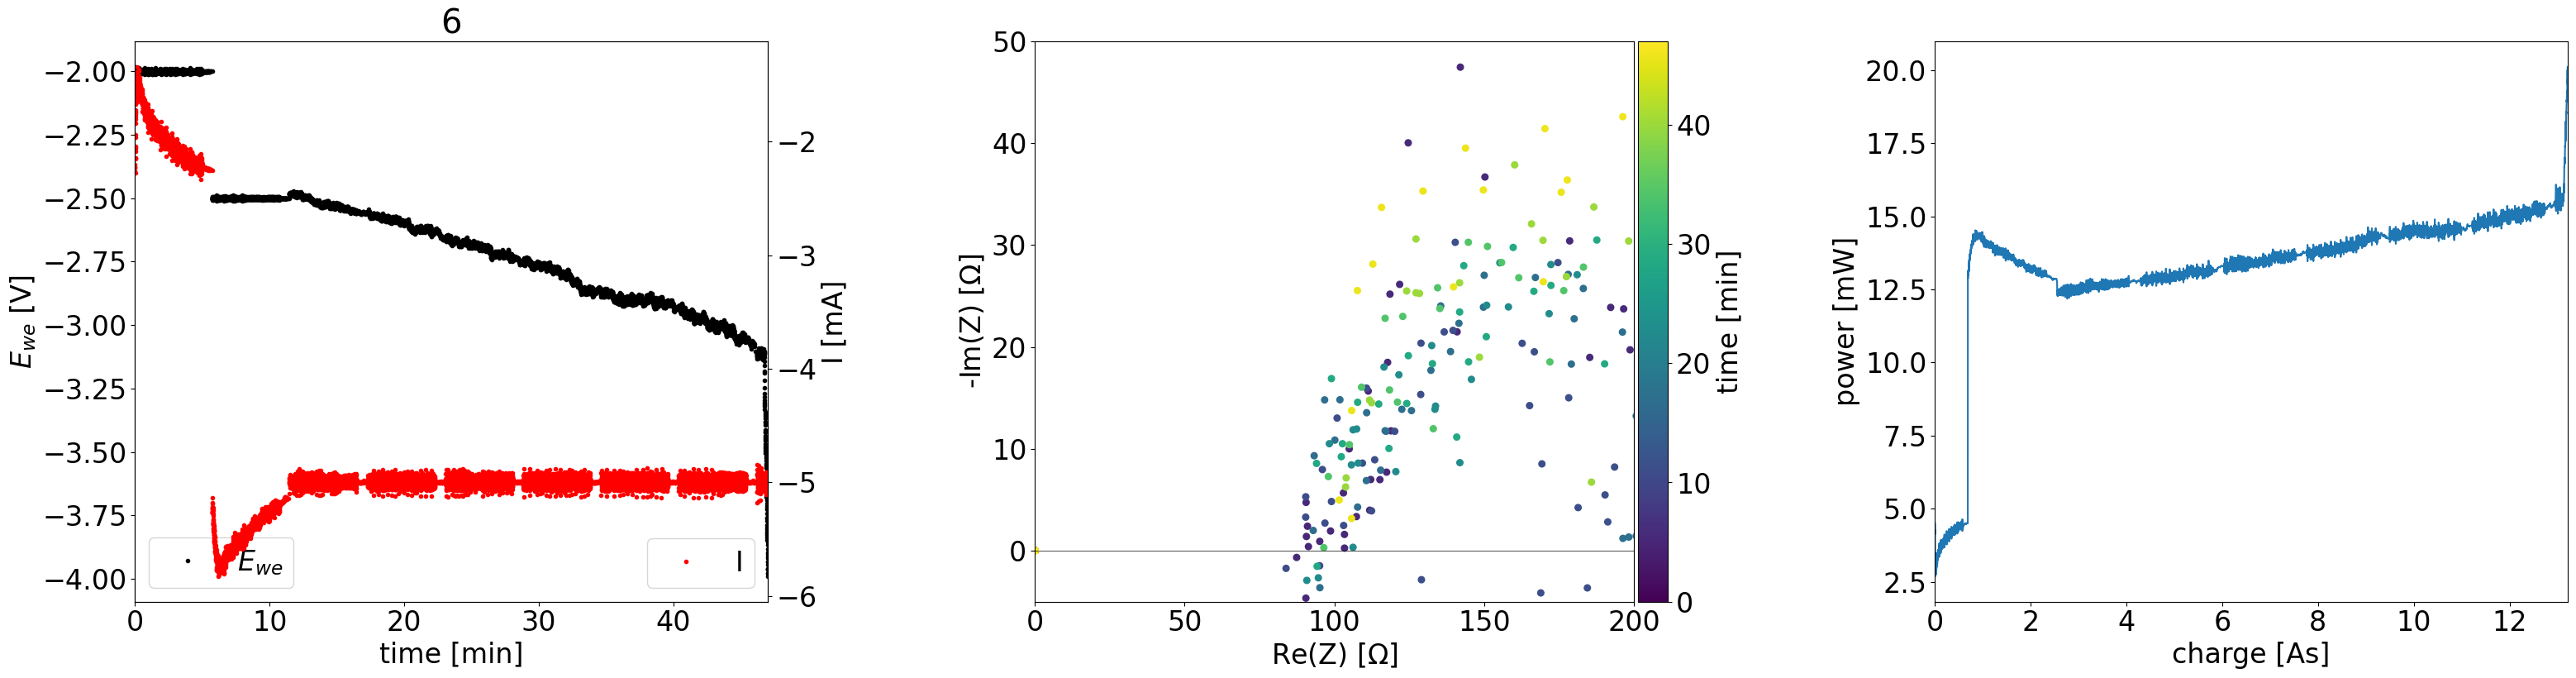

In [14]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 5
### short description

Galvanostatic operation 10mA and 15mA <br />



In [15]:
# load data TODO wrap into function and provided small dossier as dict
sample = '5'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps}

1667244335.582033


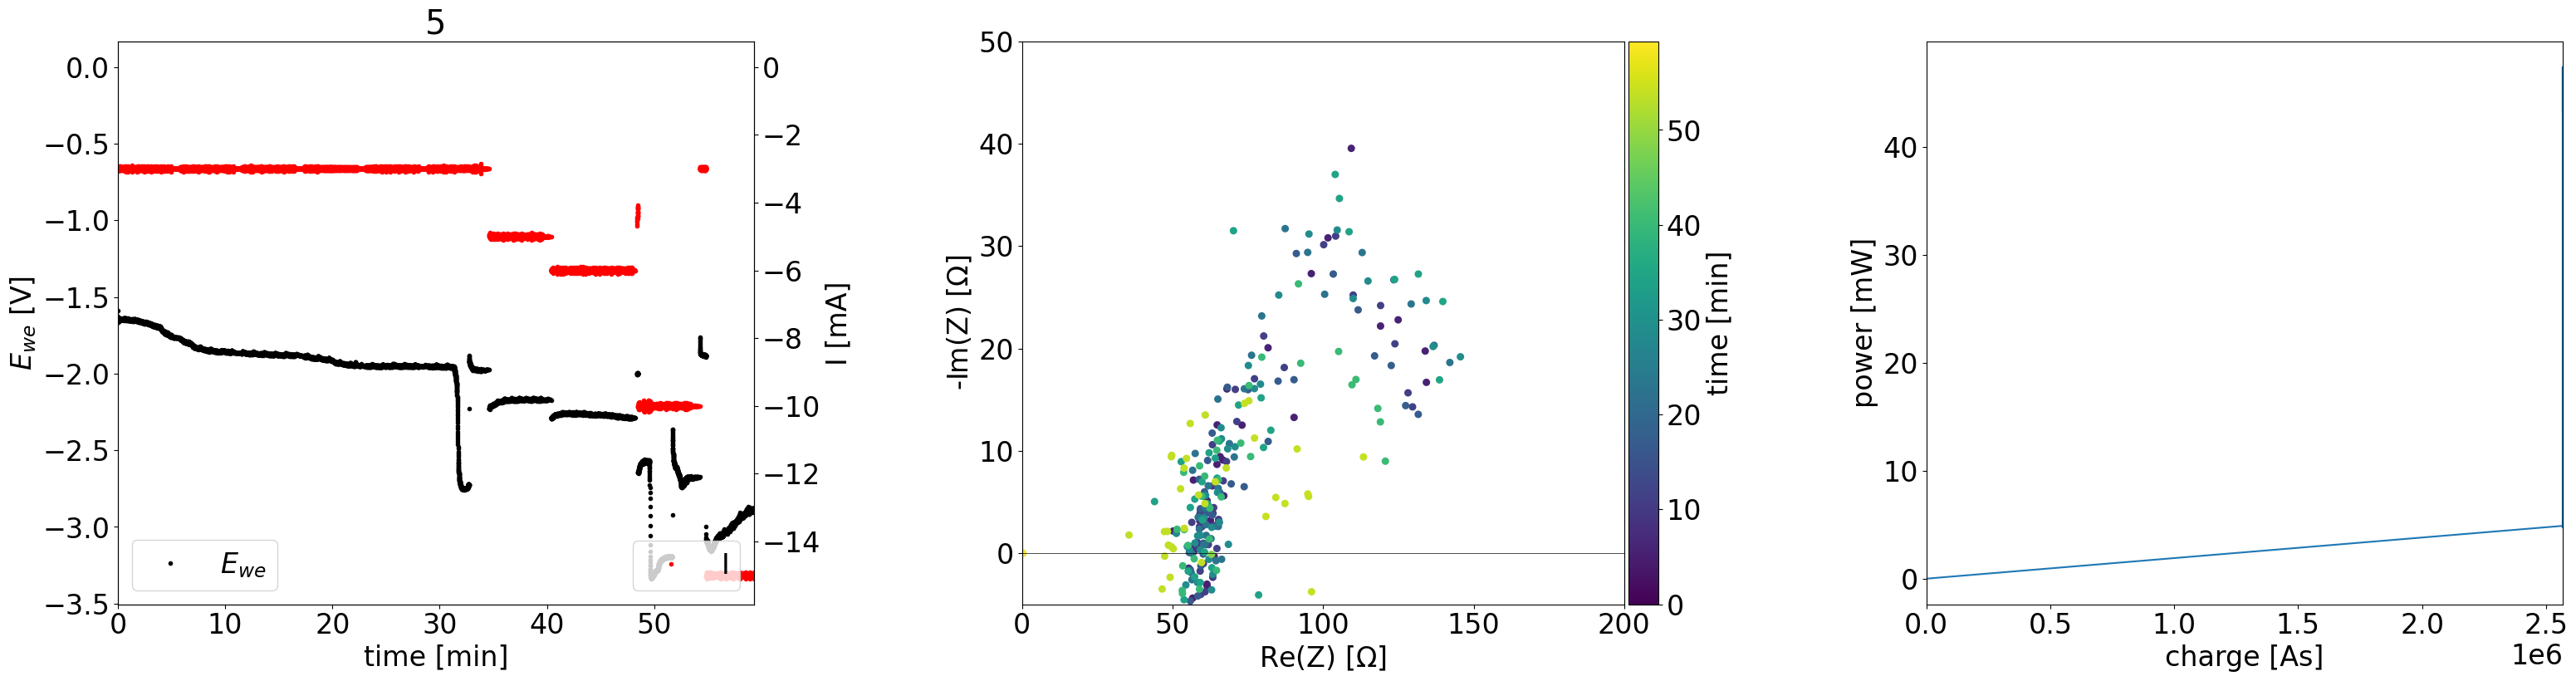

In [16]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 4II
### short description

current rampup <br />
potential safety limit overflow -> filter extreme E values



In [142]:
# load data TODO wrap into function and provided small dossier as dict
sample = '4II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re}

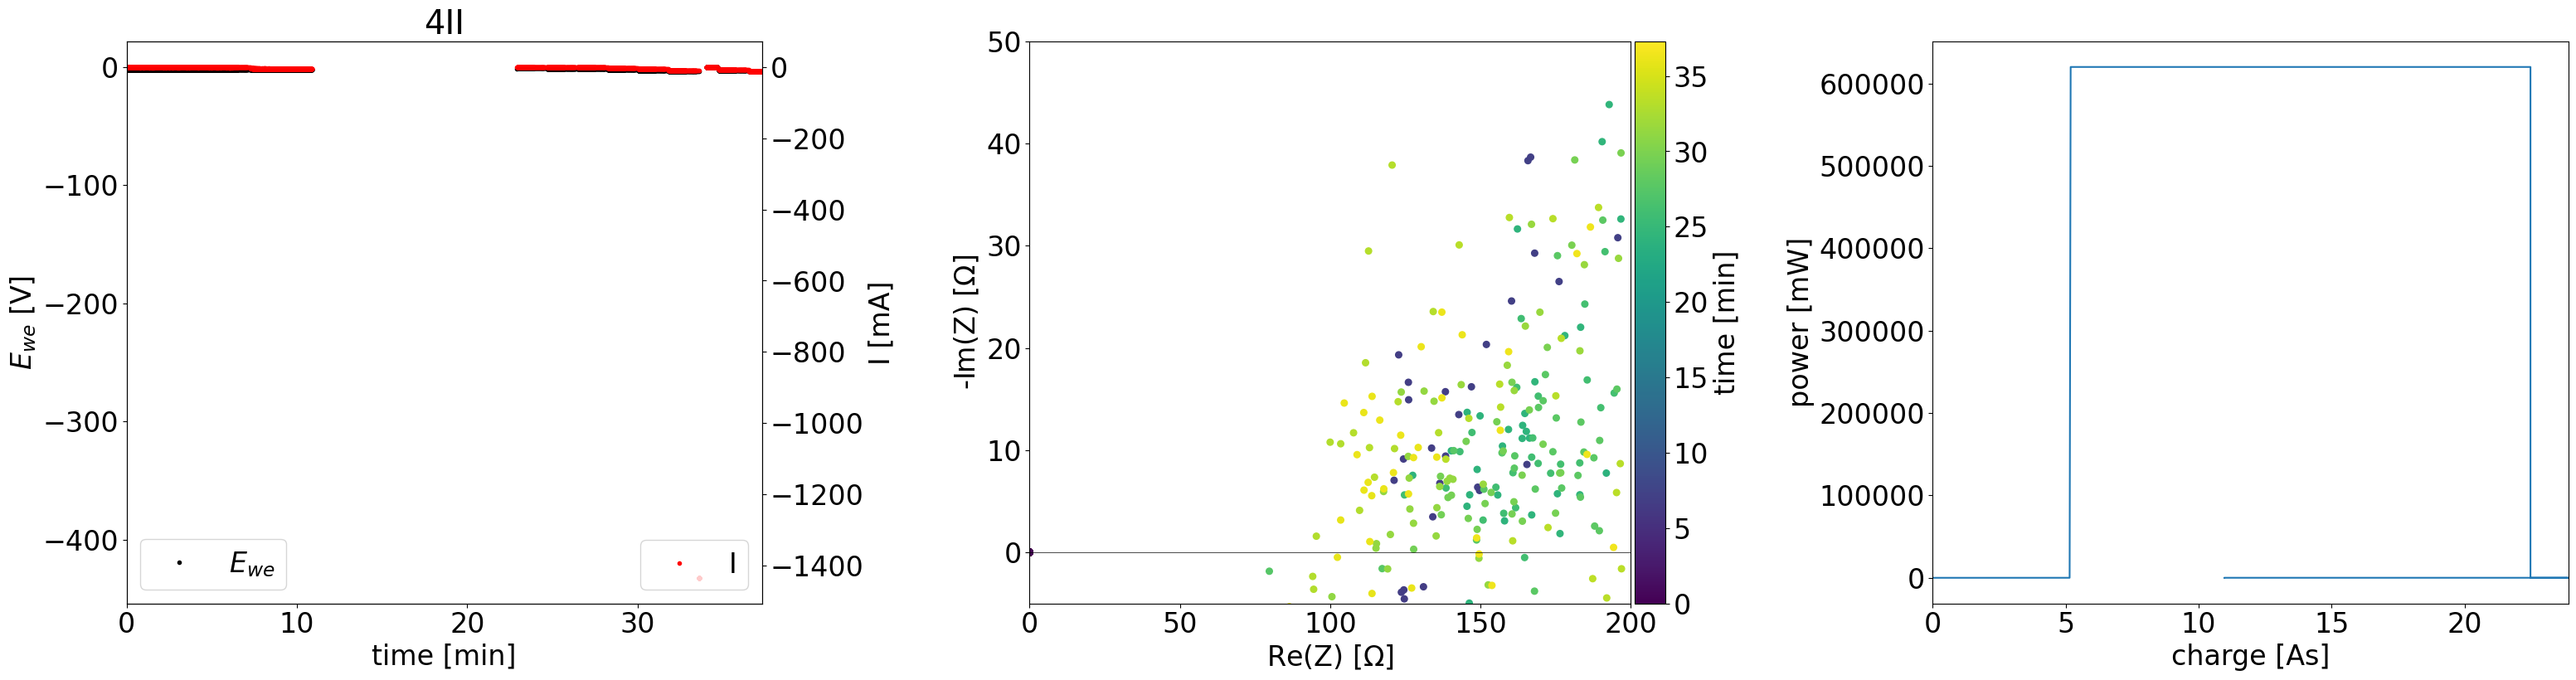

In [143]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 3III
### short description

Galvanostatic 14 mA



In [144]:
# load data TODO wrap into function and provided small dossier as dict
sample = '3III'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re}

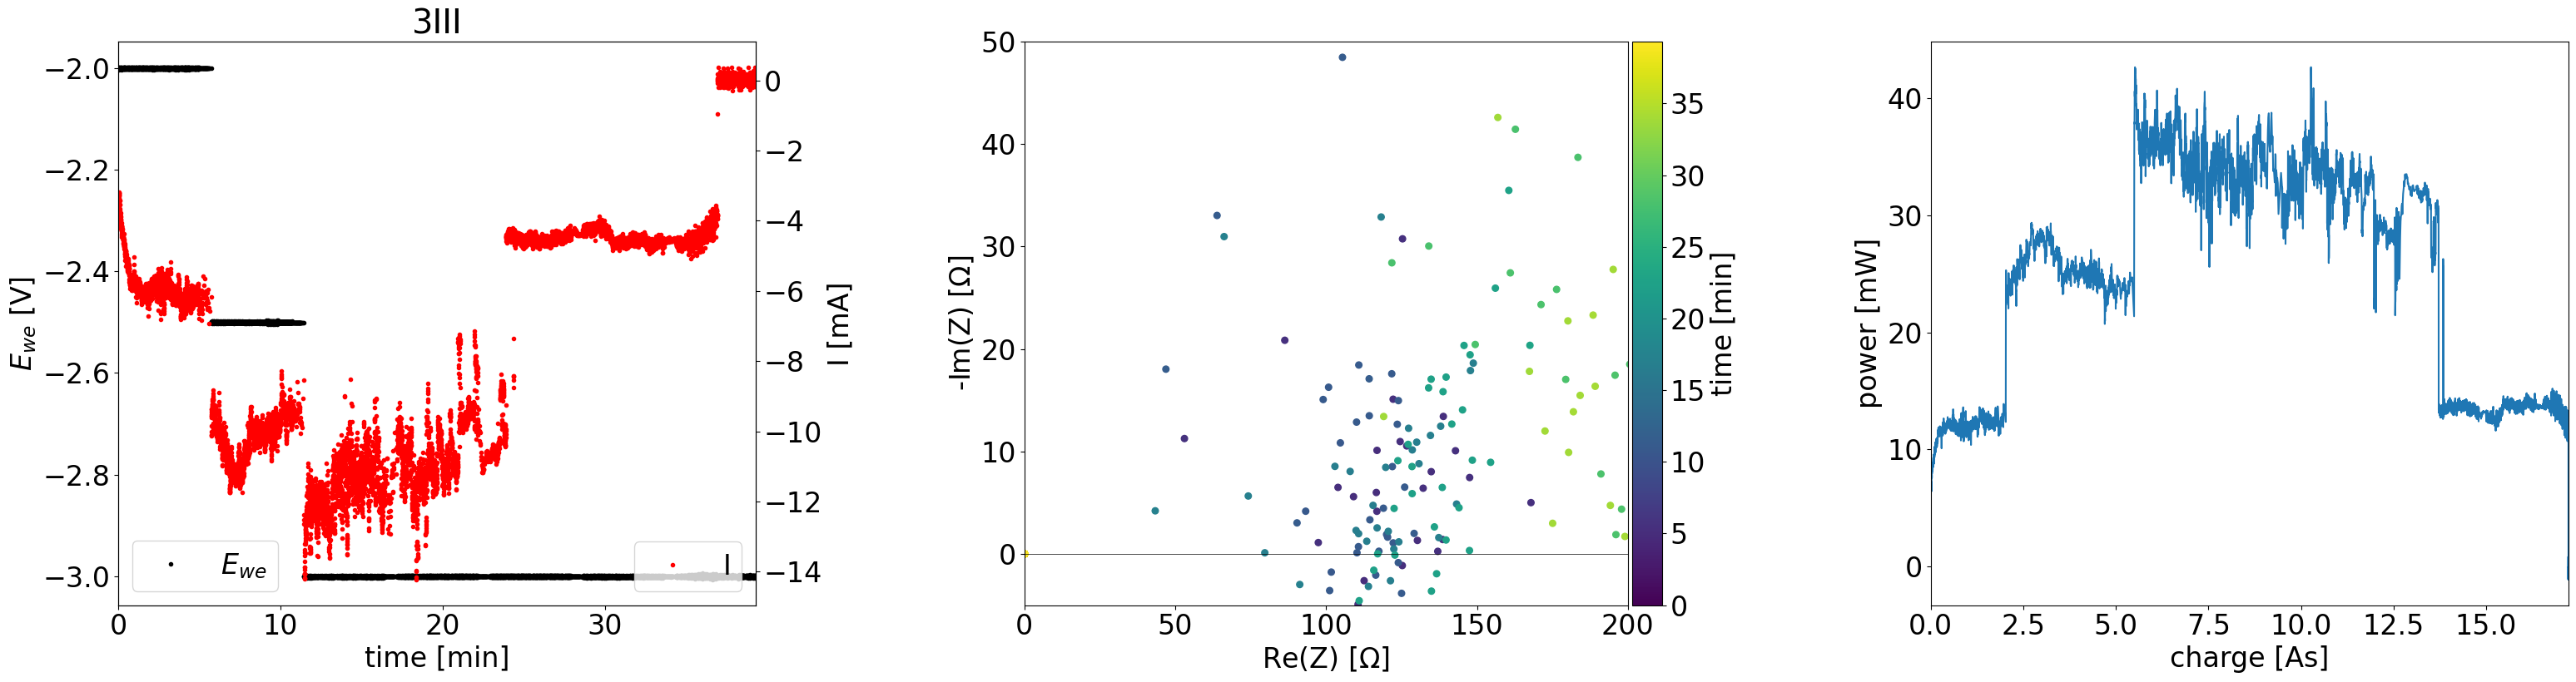

In [145]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 5
### short description

Galvanostatic operation 10mA and 15mA <br />



In [146]:
# load data TODO wrap into function and provided small dossier as dict
sample = '5'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re}

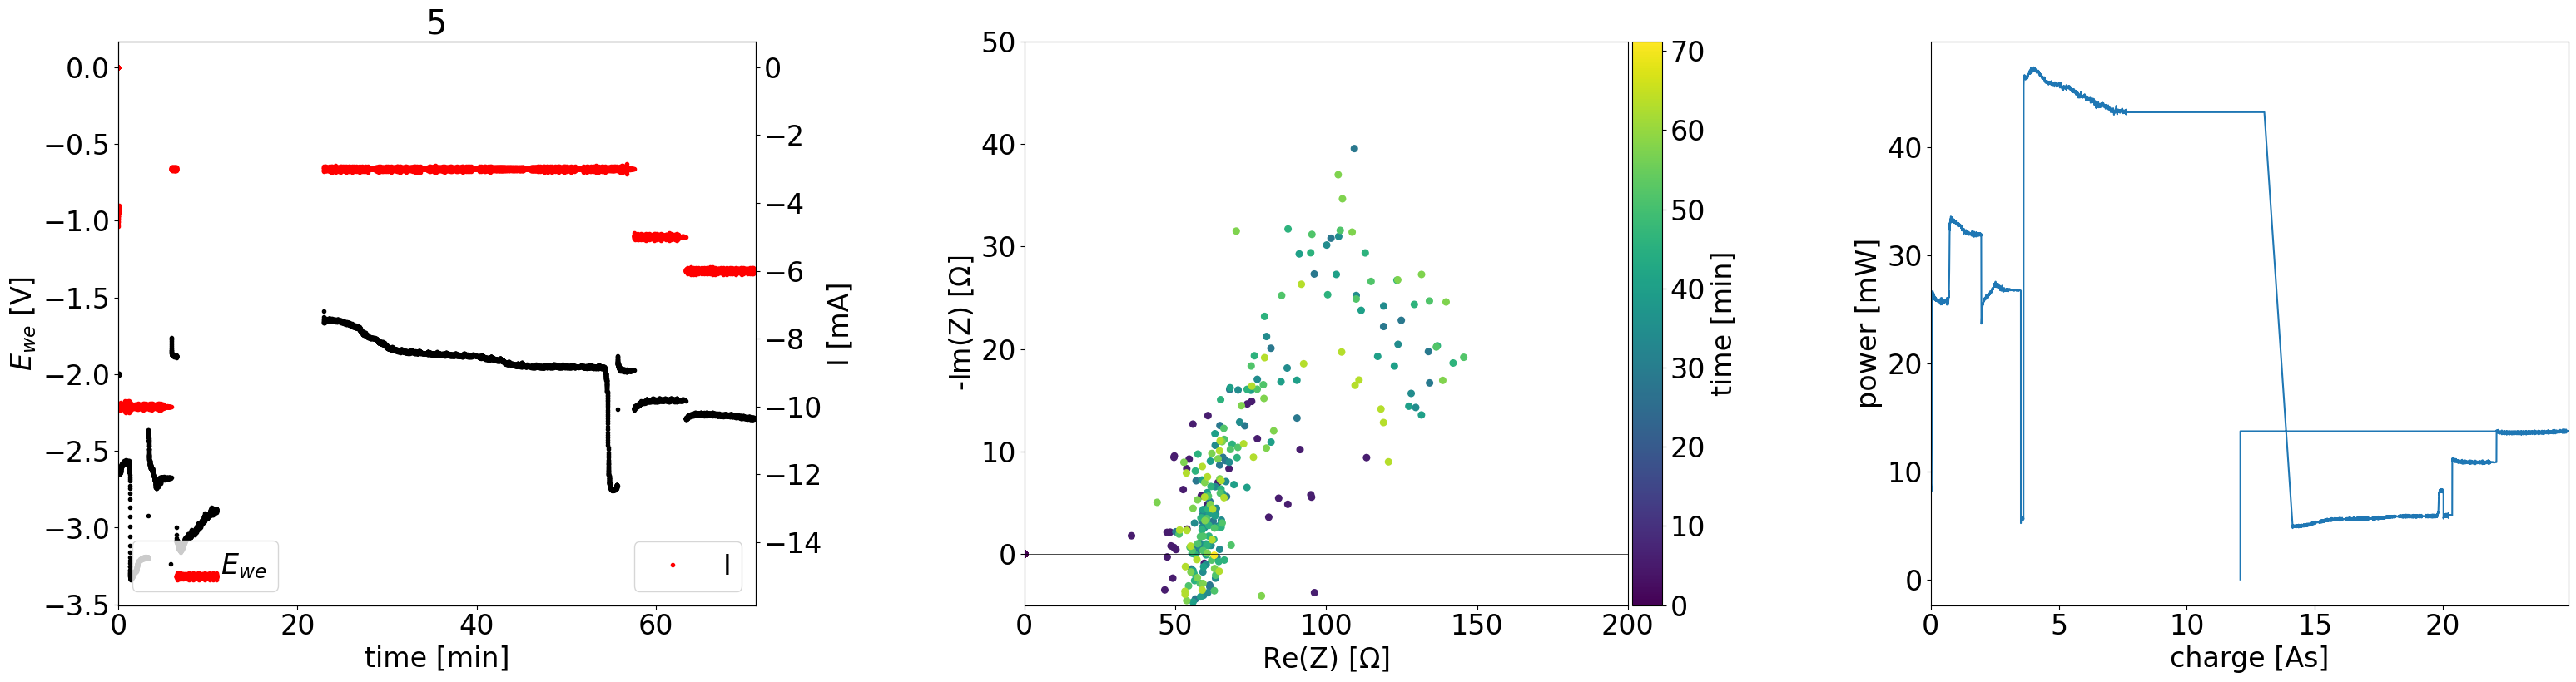

In [147]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 7x
### short description

Galvanostatic 5mA <br />
GDL with punch slits



In [148]:
# load data TODO wrap into function and provided small dossier as dict
sample = '7x'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re}

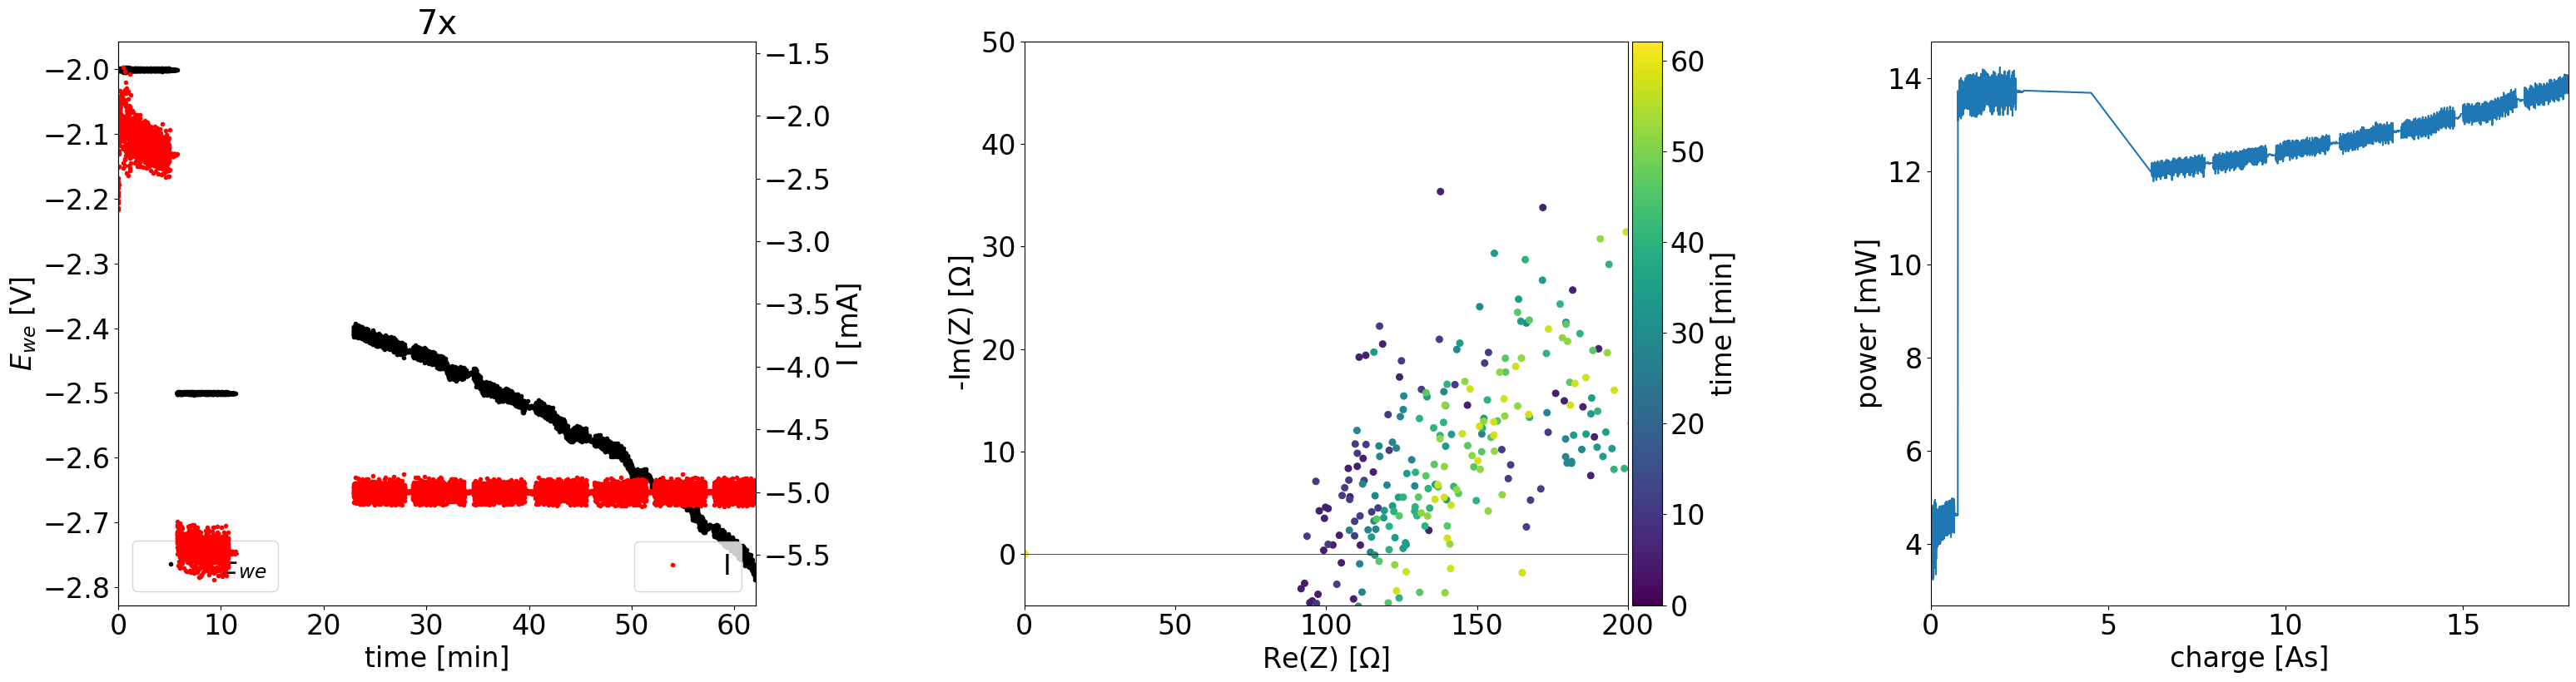

In [149]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

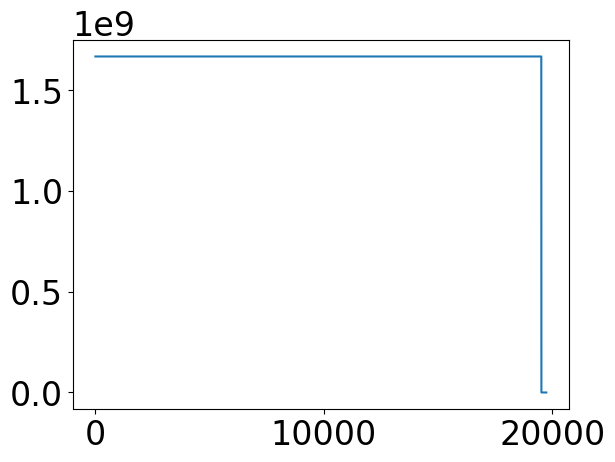

In [69]:
plt.plot(time)

In [70]:
time

array([1.66723498e+09, 1.66723498e+09, 1.66723498e+09, ...,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00])

In [71]:
np.count_nonzero(time<100)

219

In [99]:
ECdata

[<xarray.Dataset>
 Dimensions:          (t: 3074)
 Coordinates:
   * t                (t) float64 0.4666 0.6666 0.8676 ... 679.8 682.8 687.2
 Data variables: (12/35)
     freq             (t) float64 0.0 0.0 0.0 0.0 0.0 ... 3.169 2.158 1.468 1.0
     Re(Z)            (t) float64 0.0 0.0 0.0 0.0 0.0 ... 158.2 160.4 173.6 167.7
     -Im(Z)           (t) float64 -0.0 -0.0 -0.0 -0.0 ... 10.18 7.346 11.87 5.246
     |Z|              (t) float64 0.0 0.0 0.0 0.0 0.0 ... 158.6 160.6 174.0 167.8
     Phase(Z)         (t) float64 0.0 0.0 0.0 0.0 ... -3.681 -2.622 -3.911 -1.791
     time             (t) float64 0.4666 0.6666 0.8676 ... 679.8 682.8 687.2
     ...               ...
     |I h3|           (t) float64 0.0 0.0 0.0 ... 8.837e-07 2.93e-06 1.938e-06
     |I h4|           (t) float64 0.0 0.0 0.0 0.0 ... 5.8e-06 2.584e-06 1.935e-06
     |I h5|           (t) float64 0.0 0.0 0.0 ... 1.422e-06 1.215e-06 1.46e-06
     |I h6|           (t) float64 0.0 0.0 0.0 ... 2.469e-06 3.549e-06 1.736e-06
  

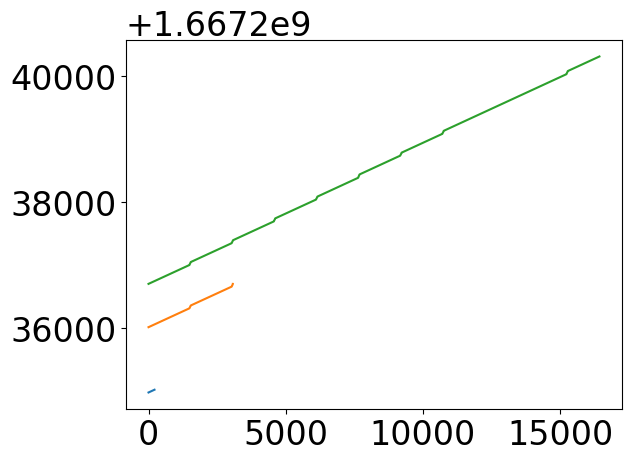

In [121]:
for d in ECdata:
    plt.plot(d['timestamp (utc)'])

In [110]:
np.count_nonzero(ECdata[0]['timestamp (utc)']<0)

0

In [111]:
mpl.rcParams["font.size"] = deffontsize

In [122]:
1000/60

16.666666666666668

In [166]:
2.5e7/60/24

17361.111111111113

In [17]:
for d in ECdata:
    print(d.attrs['path'])
    print((d['timestamp (utc)'][0].data-1667253068.8336)/60)

/mpc/homes/fische_r/NAS/DASCOELY/EC_lab_files/cell_5_scan1b_01_PEIS_C01.mpr
-97.13696666955948
/mpc/homes/fische_r/NAS/DASCOELY/EC_lab_files/cell_5_scan1b_02_GEIS_C01.mpr
-97.05080999930699
/mpc/homes/fische_r/NAS/DASCOELY/EC_lab_files/cell_5_scan1_01_PEIS_C01.mpr
-157.0319000005722
/mpc/homes/fische_r/NAS/DASCOELY/EC_lab_files/cell_5_scan1_02_GEIS_C01.mpr
-145.554192785422


In [15]:
time

array([ 0.00000000e+00,  2.00000048e-01,  4.01000023e-01, ...,
       -1.66724724e+09, -1.66724724e+09, -1.66724724e+09])

In [16]:
time.argsort()

array([20441, 17557, 17556, ...,  3071,  3072,  3073])